<a href="https://colab.research.google.com/github/Evelandya/procesamiento-del-habla/blob/tp_1/TRAMONTIN_EVELYN_PH_TP1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP1 PROCESAMIENTO DEL HABLA: webscrapping

**Crea una copia de este notebook en tu google colab**

**Renombra el notebook con el siguiente formato APELLIDO_NOMBRE_PH_TP1.ipynb**

**[Escriba aquí su nombre completo.]**


* Resolver las consignas comentando el código fuente, indicando desde dónde fue extraido o generado.

* Explicar y justificar cada paso realizado usando los bloques de texto.

* Publique enlace público a su notebook en google colab y también enlace a su repositorio github de la materia.


## EJERCICIO CONSIGNA

* Cree una nube de palabras de un texto en español.

* Dicho texto puede ser descargado de Internet (webscrapping) o extraído del dataset de alguna librería.

* Puede usar cualquier libreria o herramienta para obtener el texto de su interés.

* En este notebook explica el paso a paso del proceso.



## 1- Webscrapping

Extrae un texto de Internet de una sóla página web usando alguna de las técnicas de webscrapping vistas en clase. Busca el discurso de alguna persona quien te inspire o haya dado una charla motivadora.

No puedes repetir ni usar ni el mismo texto ni la misma web que otra persona quien ya entregó en el foro.

Abajo añade los bloques de código y texto necesarios. Explica paso a paso como descargaste el texto de tu interés.


### Instalación de Librerias

> *El codigo fue extraido del google colab "clase_2_webscrapping.ipynb" visto en clase.*




In [1]:
! pip install requests beautifulsoup4 html5lib

### Extracción del discurso

> *El codigo fue extraido del google colab "clase_2_webscrapping.ipynb" visto en clase.*




In [2]:
import requests
from bs4 import BeautifulSoup

In [3]:
# URL del discurso de Dalai Lama
url = "https://www.dalailama.com/messages/acceptance-speeches/nobel-peace-prize/nobel-peace-prize-nobel-lecture"

# Solicitud HTTP
respuesta = requests.get(url)
respuesta.raise_for_status()

In [6]:
# Analisis del contenido HTML de la página
sopa = BeautifulSoup(respuesta.text, 'html5lib')

In [9]:
# Extracción del discuso
discurso_div = sopa.find('div', class_=['grid-column fitVideos showCaptions'])
if discurso_div:
    discurso_texto = discurso_div.get_text()
else:
    discurso_texto = "No se encontró el discurso con las clases especificadas."
print(discurso_texto)


					Brothers and Sisters:
It is an honour and pleasure to be among you today. I am really happy to see so many old friends who have come from different corners of the world, and to make new friends, whom I hope to meet again in the future. When I meet people in different parts of the world, I am always reminded that we are all basically alike: we are all human beings. Maybe we have different clothes, our skin is of a different colour, or we speak different languages. That is on the surface. But basically, we are the same human beings. That is what binds us to each other. That is what makes it possible for us to understand each other and to develop friendship and closeness.
Thinking over what I might say today, I decided to share with you some of my thoughts concerning the common problems all of us face as members of the human family. Because we all share this small planet earth, we have to learn to live in harmony and peace with each other and with nature. That is not just a dream, b

## 2- Preprocesamiento

> *Parte del codigo fue extraido desde el archivo "nltk-spacy.ipynb" que vimos en clase y se potencio con ayuda de Gemini para cumplir con la consigna*




### 2.1 Muestra las stop words que tenga tu texto.

In [12]:
import nltk
from nltk.corpus import stopwords
import re

# Descarga de las stopwords de NLTK
try:
    stopwords.words('english')
except LookupError:
    nltk.download('stopwords')

# Stopwords en inglés de NLTK
stopwords_en_nltk = set(stopwords.words('english'))

# Limpieza y tokenización del texto
# Converción de minúsculas y eliminación de caracteres no alfabéticos para una mejor comparación
cleaned_text = re.sub(r'[^a-záéíóúñü\s]', '', discurso_texto.lower())
words = cleaned_text.split()

# Busqueda de las stop words en el texto
found_stopwords_nltk = set()
for word in words:
    if word in stopwords_en_nltk:
        found_stopwords_nltk.add(word)

print("Stop words encontradas en el texto:")
if found_stopwords_nltk:
    print(sorted(list(found_stopwords_nltk)))
else:
    print("No se encontraron stop words de la lista definida de NLTK en el texto.")

Stop words encontradas en el texto:
['a', 'about', 'above', 'after', 'again', 'against', 'all', 'am', 'an', 'and', 'any', 'are', 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'between', 'both', 'but', 'by', 'can', 'did', 'do', 'does', 'doing', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'has', 'have', 'here', 'how', 'i', 'if', 'in', 'into', 'is', 'it', 'its', 'just', 'me', 'more', 'most', 'my', 'no', 'not', 'now', 'of', 'on', 'once', 'only', 'or', 'other', 'our', 'ourselves', 'out', 'over', 'own', 'same', 'should', 'so', 'some', 'such', 'than', 'that', 'the', 'their', 'them', 'themselves', 'then', 'there', 'these', 'they', 'this', 'those', 'through', 'to', 'too', 'under', 'up', 'very', 'was', 'we', 'were', 'what', 'when', 'where', 'which', 'while', 'who', 'whom', 'will', 'with', 'you', 'your']


### 2.2 Quita las stop-words, caracteres extraños del texto. Utiliza el texto restante para crear una nube de palabras. Usa la biblioteca worldcloud de python.

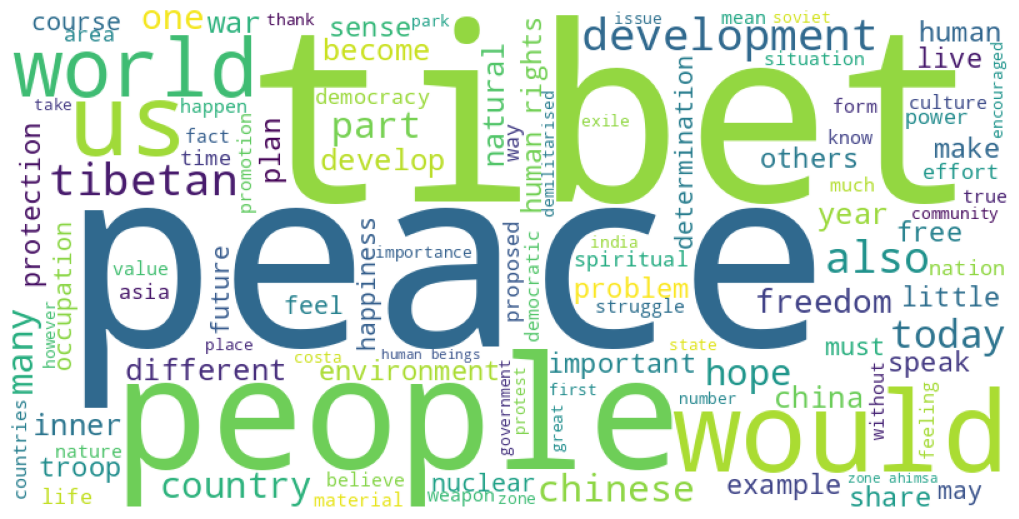

In [13]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Eliminación de caracteres no alfabéticos y conversión a minúsculas
cleaned_text_raw = re.sub(r'[^a-zA-Z\s]', '', discurso_texto.lower())

# Tokenización y eliminación de stopwords
words_filtered = [word for word in cleaned_text_raw.split() if word not in stopwords_en_nltk]

# Union de las palabras limpias de nuevo en un solo string
text_for_wordcloud = " ".join(words_filtered)

# Creación de un objeto WordCloud
wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white",
    stopwords=stopwords_en_nltk,
    min_font_size=10
).generate(text_for_wordcloud)

# Visualización de la imagen generada
plt.figure(figsize=(10, 5), facecolor=None)
plt.imshow(wordcloud)
plt.axis("off")
plt.tight_layout(pad=0)
plt.show()

### 2.3 Usando el texto que conseguiste en el punto 1).



#### 2.3.1 Limpia y preprocesa el texto, descomponelo en oraciones, arma una matriz documento-vocabulario.


In [15]:
from nltk.tokenize import sent_tokenize, word_tokenize
from sklearn.feature_extraction.text import CountVectorizer

# Descarga de los recursos de NLTK necesarios
try:
    nltk.data.find('tokenizers/punkt')
except LookupError:
    nltk.download('punkt')

try:
    nltk.data.find('tokenizers/punkt_tab')
except LookupError:
    nltk.download('punkt_tab')


# Obtención de las stopwords en inglés de NLTK
stopwords_en_nltk = set(stopwords.words('english'))

# 1. Preprocesamiento y limpiaza del texto general para tokenización por oraciones
# Eliminación de caracteres especiales y mantención de solo letras y espacios, luego conversión a minúsculas
# Mantengo algunos signos de puntuación para que sent_tokenize funcione mejor, pero los limpiaré después de la tokenización
processed_discurso_texto = re.sub(r'[^a-zA-Z.!?\s]', '', discurso_texto.lower())

# 2. Descomposición del texto en oraciones
sentences = sent_tokenize(processed_discurso_texto)

# 3. Limpieza de cada oración (documento) y eliminación de stopwords
cleaned_sentences = []
for sentence in sentences:
    # Eliminación de puntuación adicional y tokenización de palabras
    words = word_tokenize(re.sub(r'[.!?]', '', sentence))
    # Filtrado de stopwords y uniones de palabras vacías
    filtered_words = [word for word in words if word not in stopwords_en_nltk and word.strip() != '']
    cleaned_sentences.append(" ".join(filtered_words))

# Eliminación de oraciones vacías que puedan resultar del proceso de limpieza
cleaned_sentences = [s for s in cleaned_sentences if s.strip() != '']

# 4. Armado de una matriz documento-vocabulario (usando CountVectorizer)
# Cada oración limpia se considera un 'documento'
vectorizer = CountVectorizer()
document_vocabulary_matrix = vectorizer.fit_transform(cleaned_sentences)

print("Texto original limpiado y tokenizado en oraciones:")
for i, sentence in enumerate(cleaned_sentences[:5]): # Imprime solo las primeras 5 para no saturar
    print(f"Oración {i+1}: {sentence}")
if len(cleaned_sentences) > 5:
    print("...")

print(f"\nNúmero de oraciones (documentos): {document_vocabulary_matrix.shape[0]}")
print(f"Tamaño del vocabulario: {document_vocabulary_matrix.shape[1]}")
print("\nMatriz Documento-Vocabulario (primeras 5 filas, 10 columnas):")
print(document_vocabulary_matrix[:5, :10].toarray()) # Muestra una parte de la matriz


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Texto original limpiado y tokenizado en oraciones:
Oración 1: brothers sisters honour pleasure among today
Oración 2: really happy see many old friends come different corners world make new friends hope meet future
Oración 3: meet people different parts world always reminded basically alike human beings
Oración 4: maybe different clothes skin different colour speak different languages
Oración 5: surface
...

Número de oraciones (documentos): 162
Tamaño del vocabulario: 932

Matriz Documento-Vocabulario (primeras 5 filas, 10 columnas):
[[0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]]



#### 2.3.2 Determina la longitud de tu vocabulario.

In [16]:
vocabulary_length = len(vectorizer.get_feature_names_out())
print(f"La longitud del vocabulario es: {vocabulary_length}")

La longitud del vocabulario es: 932



#### 2.3.3. Aplica TF-IDF a tu matriz documento-vocabulario



> *El codigo fue extraido del sitio web https://scikit-learn.org/*



In [17]:
from sklearn.feature_extraction.text import TfidfTransformer

# La `document_vocabulary_matrix` ya contiene la frecuencia de términos (TF)
# calculada por CountVectorizer en la celda Jo4lDrtQH7-e.

# Inicialización de TfidfTransformer
tfidf_transformer = TfidfTransformer()

# Ajuste del transformador a la matriz de frecuencia de documentos y transformación de la misma
# Calculo del IDF y aplicación de TF-IDF
tfidf_matrix = tfidf_transformer.fit_transform(document_vocabulary_matrix)

print("Matriz TF-IDF generada:")
print(f"Forma de la matriz TF-IDF: {tfidf_matrix.shape}")

# Visualización de una parte de la matriz TF-IDF (las primeras 5 filas, 10 columnas)
# Nota: tfidf_matrix es una matriz dispersa, por lo que convertimos a array denso para imprimir
print("\nMatriz TF-IDF (primeras 5 filas, 10 columnas):")
print(tfidf_matrix[:5, :10].toarray())

Matriz TF-IDF generada:
Forma de la matriz TF-IDF: (162, 932)

Matriz TF-IDF (primeras 5 filas, 10 columnas):
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


Explica el formato de tu matriz resultante: documentos, vocabulario, tamaño. Brinda tus conclusiones.

La matriz TF-IDF resultante tiene un formato específico que representa numéricamente el texto extraido.

Cada fila de la matriz (documentos) corresponde a una de las oraciones limpias, es decir, "cleaned_sentences". El numero de filas es de 162, lo que significa que el discurso original se descompuso en 162 oraciones significativas después del preprocesamiento.

Cada columna de la matriz (vocabulario) corresponde a una palabra única (término) del vocabulario que "CountVectorizer" extrajo de todas las oraciones limpias. Previamente se determino que la longitud del vocabulario es 932. Esto significa que hay 932 palabras distintas en total en el discurso, una vez que se han eliminado las stopwords y los caracteres especiales. Cada columna representa una de estas 932 palabras.

El tamaño de la matriz (shape) es (162, 932). Esto se traduce en 162 filas (documentos/oraciones) y 932 columnas (palabras únicas del vocabulario). En cada celda de esta matriz, se encuentra un valor TF-IDF. Este valor indica la importancia de una palabra específica en una oración particular, en relación con el resto del corpus (todas las oraciones).

Los 0. que se ven en las primeras filas y columnas de la matriz que se imprimió indican que las primeras 5 oraciones no contienen ninguna de las primeras 10 palabras del vocabulario (ordenadas alfabéticamente por defecto).

# Conclusiones

Agregue aquí sus conclusiones sobre este trabajo práctico. Puede ser también parte del texto que posteará en el foro.

Este trabajo práctico permitio realizar un pipeline completo de procesamiento de texto, desde la extracción de contenido web hasta la representación numérica del mismo, lo cual es fundamental para muchos problemas de PNL.

En primer lugar se extrajo el discurso del Dalai Lama de una página web especifica, demostrando la capactidad de obtener datos textuales de la web.

Luego se implementó una limpieza exhaustiva del texto, incluyendo la normalización a minúsculas, la eliminación de caracteres especiales, la tokenización en oraciones y palabras, y la eliminación de stopwords. Esto es crucial para asegurar que los análisis posteriores se basen en datos relevantes y limpios.

Luego se transformó el texto cualitativo en una matriz numérica utilizando "CountVectorizer" y "TfidfTransformer". Esto convierte el texto en un formato que puede ser entendido y procesado por algoritmos de aprendizaje automático.

Finalmente al determinar la longitud del vocabulario (932 palabras), obtenemos una medida de la diversidad léxica del discurso después de la limpieza. Se puede decir que el discurso del Dalai Lama, después de un exhaustivo preprocesamiento (eliminación de stopwords y caracteres especiales), muestra una diversidad léxica considerablemente buena.
Considerando que se trata de un único discurso y no de una colección de documentos muy extensa, tener casi mil palabras distintas es un indicador de que el lenguaje utilizado no es excesivamente repetitivo y posee una buena variedad de términos. Implica que el autor aborda el tema con un vocabulario relativamente rico y variado, evitando la redundancia constante de las mismas palabras.


# Anexo, código de ejemplo del uso de wordcloud

Instalar e importar la librería

In [ ]:
# instalar wordcloud
!pip install wordcloud


In [ ]:

# Importar librerías
from wordcloud import WordCloud
import matplotlib.pyplot as plt


In [ ]:

# Texto de ejemplo
text = "Este es un texto de ejemplo para crear una nube de palabras usando word cloud. Puedes reemplazar este texto utilizando tu propio texto."

# Crear un objeto WordCloud
wordcloud = WordCloud(width=800, height=400, background_color="white").generate(text)


Mostramos la imagen generada

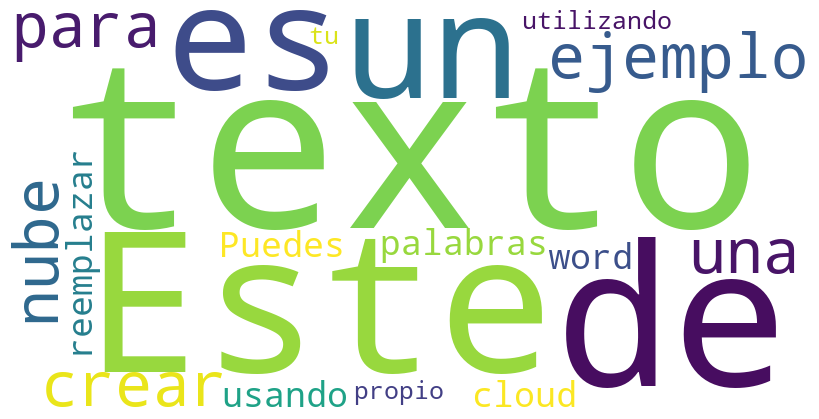

In [ ]:

# mostramos la imagen generada
plt.figure(figsize=(8, 8), facecolor=None)
plt.imshow(wordcloud)
plt.axis("off")
plt.tight_layout(pad=0)
plt.show()

Modificamos el ejemplo anterior agregando palabras en español que no queremos que considere para crear la nube de palabras. Estas son las stop_words



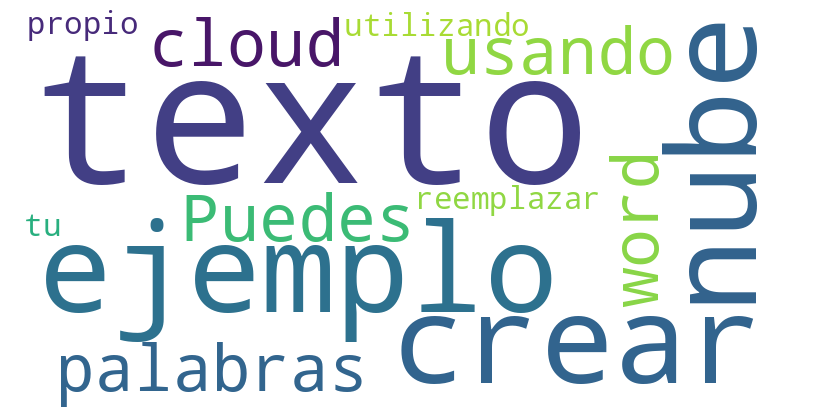

In [ ]:
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt

# Texto de ejemplo
text = "Este es un texto de ejemplo para crear una nube de palabras usando word cloud. Puedes reemplazar este texto utilizando tu propio texto."

# Definir stopwords en español
stopwords_es = set(STOPWORDS)
stopwords_es.update(["con", "que", "los", "para", "un", "una", "el", "la", "en", "y", "o", "de", "a", "se", "es", "al", "como", "por", "no", "su", "más", "pero", "si", "este", "esta", "eso", "esa", "todo", "todos", "todas", "cada", "cual", "cualquier", "algo", "alguna", "algún", "ningún", "ninguna", "ninguno", "otro", "otros", "otras", "sobre", "entre", "durante", "desde", "hasta", "también", "así", "mismo", "misma", "mismo", "misma", "tan", "tanto", "tanta", "muy", "poco", "poca", "poco", "nada", "solo", "sola", "solo", "sola", "siempre", "nunca", "jamás", "casi", "aproximadamente", "cerca", "lejos", "antes", "después", "ahora", "hoy", "ayer", "mañana", "luego", "mientras", "mientras tanto", "después de", "antes de", "durante", "sin", "aunque", "a pesar de", "debido a", "gracias a", "por qué", "cómo", "dónde", "cuándo", "quién", "qué", "cuál"])

# Crear un objeto WordCloud con stopwords en español
wordcloud = WordCloud(width=800, height=400, background_color="white", stopwords=stopwords_es).generate(text)

# Mostramos la imagen generada
plt.figure(figsize=(8, 8), facecolor=None)
plt.imshow(wordcloud)
plt.axis("off")
plt.tight_layout(pad=0)
plt.show()
